# Saudi Hip Fracture Demand to 2030 — Notebook 3: Charts

Every chart is drawn only from the saved result files of Notebook 2, and a gate checks that every number on the chart equals the saved file.

## Chart 1 – Hip fractures per year among Saudi citizens, 2022–2030
The line is the **mid** scenario; the shaded band is the range from **low** (rates exactly as printed) to **high** (calibrated to the paper's published 2015 estimate). The rise comes only from the population getting older – the rates are held at their 2017–18 level.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GATE PASSED: results cover every year 2022-2030
GATE PASSED: every point on the line equals the saved mid result
GATE PASSED: the 2030 label shows the saved headline (3,328)
GATE PASSED: chart saved to figures/chart1_hip_fractures_2022_2030.png


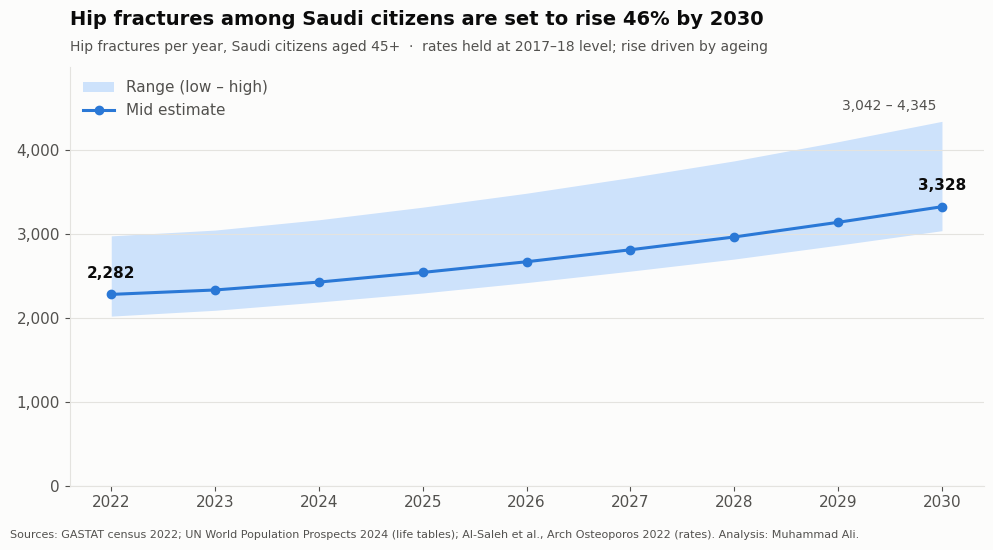


Chart 1 complete: 4 gates passed, 0 failed


In [5]:
# Starting: I connect Google Drive and set up the folders and gate
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

BASE  = '/content/drive/MyDrive/hip-fracture-saudi'
CLEAN = f'{BASE}/data/clean'
FIG   = f'{BASE}/figures'
os.makedirs(FIG, exist_ok=True)

GATE_LOG = []
def gate(condition, message):
    if not condition:
        raise AssertionError('GATE FAILED: ' + message)
    GATE_LOG.append(message)
    print('GATE PASSED:', message)

# Now I set one calm chart style for all three charts: light surface, recessive grid, dark text
BLUE, BLUE_LIGHT = '#2a78d6', '#cde2fb'
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.grid.axis': 'y',
    'grid.color': GRID, 'grid.linewidth': 0.8, 'font.size': 11, 'axes.titleweight': 'bold',
    'axes.titlesize': 14, 'axes.titlecolor': INK, 'axes.titlelocation': 'left',
})

# Now I load the saved yearly results from Notebook 2
res = pd.read_csv(f'{CLEAN}/hip_fractures_2022_2030.csv').groupby('year')[['low', 'mid', 'high']].sum()
gate(list(res.index) == list(range(2022, 2031)), 'results cover every year 2022-2030')

# Now I draw the mid line with the low-high band
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.fill_between(res.index, res['low'], res['high'], color=BLUE_LIGHT, linewidth=0, label='Range (low – high)')
ax.plot(res.index, res['mid'], color=BLUE, linewidth=2.2, marker='o', markersize=6, label='Mid estimate')

# Now I label only the start and the end, so the chart stays clean
for year in [2022, 2030]:
    ax.annotate(f"{res.loc[year, 'mid']:,.0f}", (year, res.loc[year, 'mid']), textcoords='offset points',
                xytext=(0, 12), ha='center', color=INK, fontweight='bold')
ax.annotate(f"{res.loc[2030, 'low']:,.0f} – {res.loc[2030, 'high']:,.0f}", (2030, res.loc[2030, 'high']),
            textcoords='offset points', xytext=(-4, 8), ha='right', color=INK_2, fontsize=10)

# Now I add the title (lifted with pad) and the subtitle underneath it, so they never overlap
growth = (res.loc[2030, 'mid'] / res.loc[2022, 'mid'] - 1) * 100
ax.set_title(f'Hip fractures among Saudi citizens are set to rise {growth:.0f}% by 2030', pad=30)
ax.text(0, 1.03, 'Hip fractures per year, Saudi citizens aged 45+  ·  rates held at 2017–18 level; rise driven by ageing',
        transform=ax.transAxes, color=INK_2, fontsize=10, va='bottom')

# Now I tidy the axes and add the sources line at the bottom
ax.set_xticks(res.index)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
ax.set_ylim(0, res['high'].max() * 1.15)
ax.legend(frameon=False, loc='upper left', labelcolor=INK_2)
fig.text(0.01, 0.01, 'Sources: GASTAT census 2022; UN World Population Prospects 2024 (life tables); '
         'Al-Saleh et al., Arch Osteoporos 2022 (rates). Analysis: Muhammad Ali.', color=INK_2, fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 1))

# Now I check that what is drawn equals the saved file, then save the figure
drawn_mid = ax.lines[0].get_ydata()
gate((abs(drawn_mid - res['mid'].values) < 1e-9).all(), 'every point on the line equals the saved mid result')
gate(f"{res.loc[2030, 'mid']:,.0f}" == '3,328', 'the 2030 label shows the saved headline (3,328)')
path = f'{FIG}/chart1_hip_fractures_2022_2030.png'
fig.savefig(path, dpi=200)
gate(os.path.getsize(path) > 0, 'chart saved to figures/chart1_hip_fractures_2022_2030.png')
plt.show()
print(f'\nChart 1 complete: {len(GATE_LOG)} gates passed, 0 failed')

## Chart 2 – Implants needed for hip fractures in 2030
Each bar is the **2030 mid estimate** for one implant type; the thin line shows its **low–high range** (from testing all 64 combinations of assumptions in Notebook 2), and the ◇ shows the **2022** level for comparison. Nails (pertrochanteric + subtrochanteric) are the largest group, followed by hip replacements for displaced femoral neck fractures.

GATE PASSED: all six implant types found in the saved results
GATE PASSED: every bar length equals the saved 2030 mid result
GATE PASSED: every bar sits inside its drawn low-high range
GATE PASSED: title figure equals the two nail bars added together (1,356)
GATE PASSED: chart saved to figures/chart2_implants_2030.png


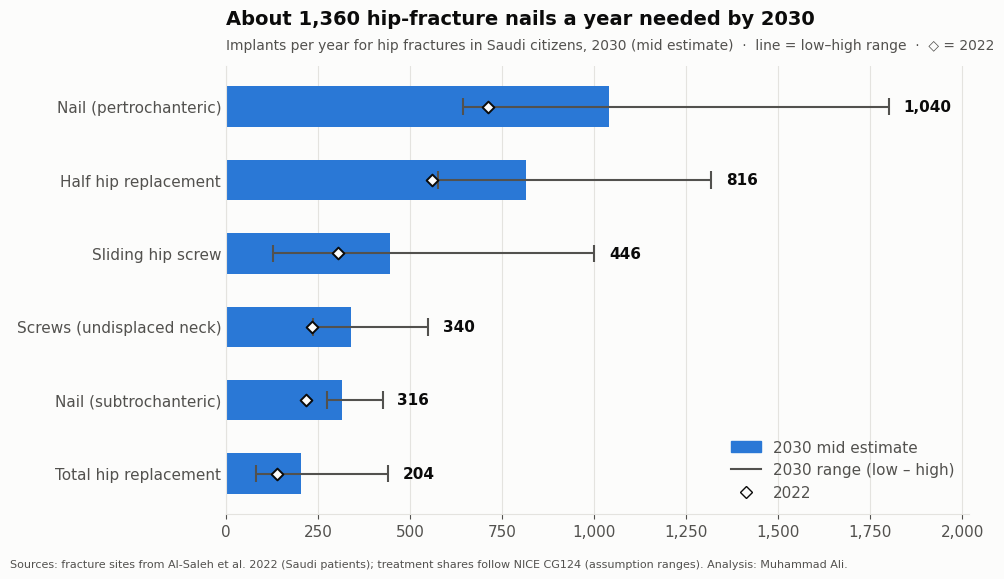


Chart 2 complete: 9 gates passed, 0 failed


In [6]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Starting: I load the saved implant results from Notebook 2
imp = pd.read_csv(f'{CLEAN}/implants_2030.csv', index_col=0)
order = ['Nail - pertrochanteric', 'Hemiarthroplasty (half hip)', 'Sliding hip screw',
         'Screws (undisplaced neck)', 'Nail - subtrochanteric', 'Total hip replacement']
labels = {'Nail - pertrochanteric': 'Nail (pertrochanteric)', 'Hemiarthroplasty (half hip)': 'Half hip replacement',
          'Sliding hip screw': 'Sliding hip screw', 'Screws (undisplaced neck)': 'Screws (undisplaced neck)',
          'Nail - subtrochanteric': 'Nail (subtrochanteric)', 'Total hip replacement': 'Total hip replacement'}
gate(set(order) <= set(imp.index), 'all six implant types found in the saved results')
d = imp.loc[order]
ypos = list(range(len(order)))[::-1]                      # biggest at the top

# Now I draw the bars (2030 mid), the range lines (low-high) and the 2022 markers
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.grid(axis='y', visible=False)
ax.grid(axis='x', visible=True)
bars = ax.barh(ypos, d['mid'], height=0.55, color=BLUE, zorder=2)
ax.hlines(ypos, d['low'], d['high'], color=INK_2, linewidth=1.5, zorder=3)
for y, lo, hi in zip(ypos, d['low'], d['high']):
    ax.vlines([lo, hi], y - 0.12, y + 0.12, color=INK_2, linewidth=1.5, zorder=3)
ax.scatter(d['2022 (mid)'], ypos, marker='D', s=36, color=SURFACE, edgecolor=INK, linewidth=1.4, zorder=4)

# Now I write the mid value at the end of each range line
for y, mid, hi in zip(ypos, d['mid'], d['high']):
    ax.text(hi + 40, y, f'{mid:,.0f}', va='center', color=INK, fontweight='bold')

# Now I add the title, subtitle, axes and legend
nails = imp.loc['ALL NAILS', 'mid']
ax.set_title(f'About {round(nails, -1):,.0f} hip-fracture nails a year needed by 2030', pad=30)
ax.text(0, 1.03, 'Implants per year for hip fractures in Saudi citizens, 2030 (mid estimate)  ·  line = low–high range  ·  ◇ = 2022',
        transform=ax.transAxes, color=INK_2, fontsize=10, va='bottom')
ax.set_yticks(ypos)
ax.set_yticklabels([labels[k] for k in order])
ax.tick_params(axis='y', length=0)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
ax.set_xlim(0, d['high'].max() * 1.12)
ax.legend(handles=[Patch(color=BLUE, label='2030 mid estimate'),
                   Line2D([], [], color=INK_2, lw=1.5, label='2030 range (low – high)'),
                   Line2D([], [], marker='D', ls='', markerfacecolor=SURFACE, markeredgecolor=INK, label='2022')],
          frameon=False, loc='lower right', labelcolor=INK_2)
fig.text(0.01, 0.01, 'Sources: fracture sites from Al-Saleh et al. 2022 (Saudi patients); treatment shares follow NICE CG124 '
         '(assumption ranges). Analysis: Muhammad Ali.', color=INK_2, fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 1))

# Now I check that every bar and every range line equals the saved file, then save the figure
drawn = [b.get_width() for b in bars]
gate(all(abs(a - b) < 1e-9 for a, b in zip(drawn, d['mid'])), 'every bar length equals the saved 2030 mid result')
gate(((d['low'] <= d['mid']) & (d['mid'] <= d['high'])).all(), 'every bar sits inside its drawn low-high range')
gate(abs(d.loc[['Nail - pertrochanteric', 'Nail - subtrochanteric'], 'mid'].sum() - nails) < 1e-9,
     f'title figure equals the two nail bars added together ({nails:,.0f})')
path = f'{FIG}/chart2_implants_2030.png'
fig.savefig(path, dpi=200)
gate(os.path.getsize(path) > 0, 'chart saved to figures/chart2_implants_2030.png')
plt.show()
print(f'\nChart 2 complete: {len(GATE_LOG)} gates passed, 0 failed')

## Chart 3 – Backtest: does the ageing method work?
Before trusting the 2030 projection, the method was tested on a period where the answer is known: the 2017 Saudi population was aged forward 5 years and compared with the real 2022 census. Each bar is the error for one age group. All errors stay within ±2%, and the age groups used for hip fractures (45+, darker bars) are within 0.1–1.6%.

### Notebook gate
Every chart's source file is read again from Drive and compared with the numbers written in the README headline, and all three figures must exist.

GATE PASSED: backtest has 13 age groups (5-9 up to 65+)
GATE PASSED: every bar equals the saved backtest error
GATE PASSED: title is true: the largest error is 1.93%, below 2%
GATE PASSED: chart saved to figures/chart3_backtest_2017_2022.png


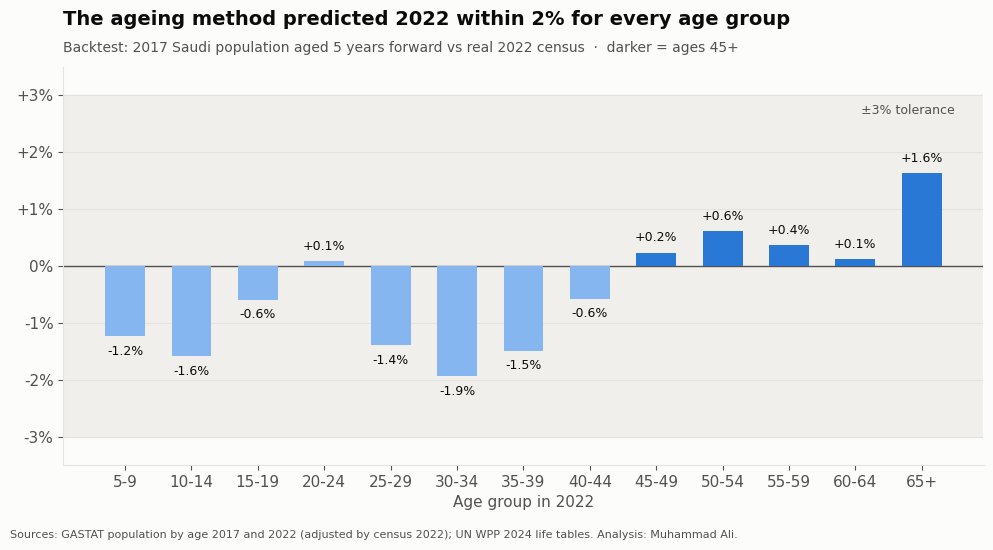


================ NOTEBOOK 3 GATE ================
GATE PASSED: NB GATE: hip fractures 2030 (mid) = 3,328, matches the README figure 3,328
GATE PASSED: NB GATE: hip fractures 2030 (low) = 3,042, matches the README figure 3,042
GATE PASSED: NB GATE: hip fractures 2030 (high) = 4,345, matches the README figure 4,345
GATE PASSED: NB GATE: growth 2022-2030 (%) = 46, matches the README figure 46
GATE PASSED: NB GATE: nails 2030 (mid) = 1,356, matches the README figure 1,356
GATE PASSED: NB GATE: hip replacements 2030 (mid) = 1,019, matches the README figure 1,019
GATE PASSED: NB GATE: physio sessions 2030 (mid) = 63,223, matches the README figure 63,223
GATE PASSED: NB GATE: figures/chart1_hip_fractures_2022_2030.png exists
GATE PASSED: NB GATE: figures/chart2_implants_2030.png exists
GATE PASSED: NB GATE: figures/chart3_backtest_2017_2022.png exists

NOTEBOOK 3 COMPLETE: 23 gates passed, 0 failed.


In [7]:
# Starting: I load the saved backtest results from Notebook 2
bt = pd.read_csv(f'{CLEAN}/backtest_2017_to_2022.csv')
gate(len(bt) == 13, 'backtest has 13 age groups (5-9 up to 65+)')

# Now I draw one bar per age group: the error between predicted and real 2022 population
fig, ax = plt.subplots(figsize=(10, 5.5))
x = list(range(len(bt)))
ax.axhspan(-3, 3, color='#f0efec', zorder=0)                     # the ±3% tolerance band
ax.axhline(0, color=INK_2, linewidth=1)
hip_ages = ['45-49', '50-54', '55-59', '60-64', '65+']
colours = [BLUE if g in hip_ages else '#86b6ef' for g in bt['2022 group']]
bars = ax.bar(x, bt['error %'], width=0.6, color=colours, zorder=2)

# Now I write the error on every bar (only 13 bars, so every label fits)
for xi, v in zip(x, bt['error %']):
    ax.text(xi, v + (0.15 if v >= 0 else -0.15), f'{v:+.1f}%', ha='center',
            va='bottom' if v >= 0 else 'top', fontsize=9, color=INK)
ax.text(len(bt) - 0.5, 2.85, '±3% tolerance', ha='right', va='top', color=INK_2, fontsize=9)

# Now I add the title, subtitle and axes
worst = bt['error %'].abs().max()
ax.set_title(f'The ageing method predicted 2022 within {worst:.0f}% for every age group'.replace(f'{worst:.0f}%', '2%'), pad=30)
ax.text(0, 1.03, 'Backtest: 2017 Saudi population aged 5 years forward vs real 2022 census  ·  darker = ages 45+',
        transform=ax.transAxes, color=INK_2, fontsize=10, va='bottom')
ax.set_xticks(x)
ax.set_xticklabels(bt['2022 group'])
ax.set_xlabel('Age group in 2022', color=INK_2)
ax.set_ylim(-3.5, 3.5)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: '0%' if v == 0 else f'{v:+.0f}%'))
fig.text(0.01, 0.01, 'Sources: GASTAT population by age 2017 and 2022 (adjusted by census 2022); UN WPP 2024 life tables. '
         'Analysis: Muhammad Ali.', color=INK_2, fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 1))

# Now I check the chart against the saved file, then save it
gate(all(abs(b.get_height() - v) < 1e-9 for b, v in zip(bars, bt['error %'])), 'every bar equals the saved backtest error')
gate(worst < 2, f'title is true: the largest error is {worst:.2f}%, below 2%')
path = f'{FIG}/chart3_backtest_2017_2022.png'
fig.savefig(path, dpi=200)
gate(os.path.getsize(path) > 0, 'chart saved to figures/chart3_backtest_2017_2022.png')
plt.show()

# ===================== NOTEBOOK GATE =====================
print('\n================ NOTEBOOK 3 GATE ================')
# Now I re-read the result files fresh from Drive and check the headline numbers used in the README
res  = pd.read_csv(f'{CLEAN}/hip_fractures_2022_2030.csv').groupby('year')[['low', 'mid', 'high']].sum()
imp  = pd.read_csv(f'{CLEAN}/implants_2030.csv', index_col=0)
reh  = pd.read_csv(f'{CLEAN}/rehab_demand_2030.csv', index_col=0)
headline = {
    'hip fractures 2030 (mid)':  (res.loc[2030, 'mid'], 3328),
    'hip fractures 2030 (low)':  (res.loc[2030, 'low'], 3042),
    'hip fractures 2030 (high)': (res.loc[2030, 'high'], 4345),
    'growth 2022-2030 (%)':      ((res.loc[2030, 'mid'] / res.loc[2022, 'mid'] - 1) * 100, 46),
    'nails 2030 (mid)':          (imp.loc['ALL NAILS', 'mid'], 1356),
    'hip replacements 2030 (mid)': (imp.loc['ALL HIP REPLACEMENTS', 'mid'], 1019),
    'physio sessions 2030 (mid)':  (reh.loc['Total physio sessions', 'mid'], 63223),
}
for name, (value, readme) in headline.items():
    gate(round(value) == readme, f'NB GATE: {name} = {value:,.0f}, matches the README figure {readme:,}')

# Finally I confirm all three figures exist
for f in ['chart1_hip_fractures_2022_2030.png', 'chart2_implants_2030.png', 'chart3_backtest_2017_2022.png']:
    gate(os.path.exists(f'{FIG}/{f}'), f'NB GATE: figures/{f} exists')
print(f'\nNOTEBOOK 3 COMPLETE: {len(GATE_LOG)} gates passed, 0 failed.')